# Sommer et al. 2026

Code used to 

I) analyze data, 

II) simulate, 

III) plot results, 

of Padamsey et al. 2022 [1] data.

[1] Padamsey, Z., Katsanevaki, D., Dupuy, N. & Rochefort, N. L. Neocortex saves energy by reducing coding precision during food scarcity. Neuron 110, 280-296.e10 (2022).


In [1]:
# import plotting functions
import Functions.data_analysis_Padamsey_natural_scenes_functions as dafPns
import Functions.synaptic_input_functions as sif
import Functions.analysis_functions as af
import Functions.simulation_functions as sf
import Functions.energy_dependent_IF_functions as edIF
import Functions.plotting_functions as pf
import Functions.paper_energy_dependent_IF_plotting_functions as ppf

# import packages
import pickle as pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.patches import Patch, FancyArrowPatch
from brian2 import *

color_CTR = 'black'
color_FR = 'red'
color_CTR_like='#4a61e8'
color_FR_like='#c41c5f'
color_FR_non_mult_scale = 'darkred'
color_FR_excitability_first = '#A23E48'
color_V_rest_var = 'darkcyan'
color_V_thresh_var = 'darkviolet'
color_exc = 'coral'
color_inh = 'cornflowerblue'


color_w_e='#2e7d32'
color_r_e='#8B0000'
color_input_exc=color_r_e
color_input_inh='lightskyblue'

colors_ad = [tuple(c) for c in plt.cm.Blues(np.linspace(0.25, 0.85, 5))]  # bright -> dark
color_AP_no_ad='darkgrey'
color_AP_ad='mediumblue'
color_K = "#556B2F"
color_Na = "#D2691E"
color_Ca = "#2A9DF4"
color_h = "#3C9A87"


color_bar_information_per_energy = 'viridis'

panelletterfontsize = ppf.set_paper_style()
fontsizes={'panelletterfontsize': panelletterfontsize}

In [74]:

import importlib 
importlib.reload(pf)
importlib.reload(ppf)
importlib.reload(edIF)

<module 'Functions.energy_dependent_IF_functions' from '/Users/psommer/Desktop/Energy-function-trade-off/Code/Functions/energy_dependent_IF_functions.py'>

## Graphical abstract

## Energy-dependent IF: synapse-first proportional derivative control 

In [ ]:
# generating Fig. data

# define homogeneous synaptic input
T = 1000000 # in ms
N_syn, N_e, N_e_signal_ratio, N_i, rate_background_ratio, mu_rate_e, sigma_rate_e, mu_rate_i, sigma_rate_i, mu_weight_e, sigma_weight_e, mu_weight_i, sigma_weight_i = sif.synaptic_parameters(synaptic_scaling_mode='multiplicative')
w_e_0, w_i_0, spike_times_e, spike_times_i, r_e, r_i = sif.homogeneous_synaptic_input(T, N_e, N_i, mu_rate_e, sigma_rate_e, mu_rate_i, sigma_rate_i, mu_weight_e, sigma_weight_e, mu_weight_i, sigma_weight_i)

factor_w = 0.7
w_e = w_e_0 * 4 / 100 * factor_w
w_i = w_i_0 * 1 / 100 * factor_w

# simulate proportional energy-control and proportional-derivative rate-control
# load model parameters
C_m, V_rest, R_m, g_L, V_thresh, V_reset, Delta_T_ad, tau_w_ad, a_ad, b_ad, rate_window, tau_Ca, A_Ca, E_e, E_i, tau_e, tau_i, membrane_noise, rho_E_target, s_E, E_target_ATP, r_target, tau_r_smooth, tau_r_deriv, tau_E_smooth, dt_sim, dt_energy, tau_w_scale, tau_V_rest, tau_R_m, E_HK, V_Na, V_K, V_h, alpha_atp, e_c, A_R_m, A_overlap_AP, A_overlap_syn, d_axon, l_axon, d_soma, d_dendrite, l_dendrite, c_m_area, V_peak, N_boutons, E_glu_rec, E_Ca_ex = edIF.energy_dependent_sim_parameters(parameter_mode='CTR', membrane_noise=0.0, s_E=0.85)
# convert parameters to Brian2 units
T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, Delta_T_ad_b, tau_w_ad_b, a_ad_b, b_ad_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex = edIF.energy_parameters_brian(T, N_e, N_i, spike_times_e, spike_times_i, w_e, w_i, C_m, V_rest, R_m, g_L, V_thresh, V_reset, Delta_T_ad, tau_w_ad, a_ad, b_ad, rate_window, tau_Ca, A_Ca, E_e, E_i, tau_e, tau_i, membrane_noise, rho_E_target, s_E, E_target_ATP, r_target, tau_r_smooth, tau_r_deriv, tau_E_smooth, dt_sim, dt_energy, tau_w_scale, tau_V_rest, tau_R_m, E_HK, V_Na, V_K, V_h, alpha_atp, e_c, A_R_m, A_overlap_AP, A_overlap_syn, d_axon, l_axon, d_soma, d_dendrite, l_dendrite, c_m_area, V_peak, N_boutons, E_glu_rec, E_Ca_ex)

# CTR condition
s_E_CTR = 1.0
#time_CTR_PD, V_m_CTR_PD, spike_times_post_CTR_PD, rate_estimate_post_CTR_PD, I_syn_e_CTR_PD, I_syn_i_CTR_PD, g_e_CTR_PD, g_i_CTR_PD, E_cons_dyn_CTR_PD, E_prod_dyn_CTR_PD, rho_E_CTR_PD, rho_E_smooth_CTR_PD, rho_E_P_control_dyn_CTR_PD, r_Ca_CTR_PD, r_Ca_dyn_smooth_CTR_PD, dr_Ca_dyn_smooth_CTR_PD, r_PD_control_dyn_CTR_PD, w_syn_e_dyn_CTR_PD, V_rest_dyn_CTR_PD, R_m_dyn_CTR_PD = edIF.energy_dependent_LIF_P_energy_PD_rate_control(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_CTR, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex)
time_CTR_PD, V_m_CTR_PD, w_ad_CTR_PD, spike_times_post_CTR_PD, rate_estimate_post_CTR_PD, I_syn_e_CTR_PD, I_syn_i_CTR_PD, g_e_CTR_PD, g_i_CTR_PD, E_cons_dyn_CTR_PD, E_prod_dyn_CTR_PD, rho_E_CTR_PD, rho_E_smooth_CTR_PD, rho_E_P_control_dyn_CTR_PD, r_Ca_CTR_PD, r_Ca_dyn_smooth_CTR_PD, dr_Ca_dyn_smooth_CTR_PD, r_PD_control_dyn_CTR_PD, w_syn_e_dyn_CTR_PD, V_rest_dyn_CTR_PD, R_m_dyn_CTR_PD = edIF.energy_dependent_AdExp_P_energy_PD_rate_control(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, Delta_T_ad_b, tau_w_ad_b, a_ad_b, b_ad_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_CTR, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex)

# FR condition
s_E_FR = 0.85
#time_FR_PD, V_m_FR_PD, spike_times_post_FR_PD, rate_estimate_post_FR_PD, I_syn_e_FR_PD, I_syn_i_FR_PD, g_e_FR_PD, g_i_FR_PD, E_cons_dyn_FR_PD, E_prod_dyn_FR_PD, rho_E_FR_PD, rho_E_smooth_FR_PD, rho_E_P_control_dyn_FR_PD, r_Ca_FR_PD, r_Ca_dyn_smooth_FR_PD, dr_Ca_dyn_smooth_FR_PD, r_PD_control_dyn_FR_PD, w_syn_e_dyn_FR_PD, V_rest_dyn_FR_PD, R_m_dyn_FR_PD = edIF.energy_dependent_LIF_P_energy_PD_rate_control(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_FR, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex)
time_FR_PD, V_m_FR_PD, w_ad_FR_PD, spike_times_post_FR_PD, rate_estimate_post_FR_PD, I_syn_e_FR_PD, I_syn_i_FR_PD, g_e_FR_PD, g_i_FR_PD, E_cons_dyn_FR_PD, E_prod_dyn_FR_PD, rho_E_FR_PD, rho_E_smooth_FR_PD, rho_E_P_control_dyn_FR_PD, r_Ca_FR_PD, r_Ca_dyn_smooth_FR_PD, dr_Ca_dyn_smooth_FR_PD, r_PD_control_dyn_FR_PD, w_syn_e_dyn_FR_PD, V_rest_dyn_FR_PD, R_m_dyn_FR_PD = edIF.energy_dependent_AdExp_P_energy_PD_rate_control(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, Delta_T_ad_b, tau_w_ad_b, a_ad_b, b_ad_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_FR, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex)

# downsample data for smaller storage capacity
data_CTR_PD = {"time": time_CTR_PD, "V_m": V_m_CTR_PD, "w_ad": w_ad_CTR_PD, "spike_times_post": spike_times_post_CTR_PD, "rate_estimate_post": rate_estimate_post_CTR_PD, "I_syn_e": I_syn_e_CTR_PD, "I_syn_i": I_syn_i_CTR_PD, "g_e": g_e_CTR_PD, "g_i": g_i_CTR_PD, "E_cons_dyn": E_cons_dyn_CTR_PD, "E_prod_dyn": E_prod_dyn_CTR_PD, "rho_E": rho_E_CTR_PD, "rho_E_smooth": rho_E_smooth_CTR_PD, "rho_E_P_control_dyn": rho_E_P_control_dyn_CTR_PD, "r_Ca": r_Ca_CTR_PD, "r_Ca_smooth": r_Ca_dyn_smooth_CTR_PD, "dr_Ca_smooth": dr_Ca_dyn_smooth_CTR_PD, "r_PD_control_dyn": r_PD_control_dyn_CTR_PD, "w_syn_e_dyn": w_syn_e_dyn_CTR_PD, "V_rest_dyn": V_rest_dyn_CTR_PD, "R_m_dyn": R_m_dyn_CTR_PD, "rho_E_target": rho_E_target, "r_target": r_target_b/Hz, "s_E": s_E_CTR}
data_FR_PD = {"time": time_FR_PD, "V_m": V_m_FR_PD, "w_ad": w_ad_FR_PD, "spike_times_post": spike_times_post_FR_PD, "rate_estimate_post": rate_estimate_post_FR_PD, "I_syn_e": I_syn_e_FR_PD, "I_syn_i": I_syn_i_FR_PD, "g_e": g_e_FR_PD, "g_i": g_i_FR_PD, "E_cons_dyn": E_cons_dyn_FR_PD, "E_prod_dyn": E_prod_dyn_FR_PD, "rho_E": rho_E_FR_PD, "rho_E_smooth": rho_E_smooth_FR_PD, "rho_E_P_control_dyn": rho_E_P_control_dyn_FR_PD, "r_Ca": r_Ca_FR_PD, "r_Ca_smooth": r_Ca_dyn_smooth_FR_PD, "dr_Ca_smooth": dr_Ca_dyn_smooth_FR_PD, "r_PD_control_dyn": r_PD_control_dyn_FR_PD, "w_syn_e_dyn": w_syn_e_dyn_FR_PD, "V_rest_dyn": V_rest_dyn_FR_PD, "R_m_dyn": R_m_dyn_FR_PD, "rho_E_target": rho_E_target, "r_target": r_target_b/Hz, "s_E": s_E_FR}

data_CTR_PD_downsampled = edIF.downsample_energy_data_dict(data_CTR_PD, downsample_factor)
data_FR_PD_downsampled = edIF.downsample_energy_data_dict(data_FR_PD, downsample_factor)

with open("../Data/energy_dependent_IF/energy_IF_CTR_FR_PPD_synapse_first_downsampled.pkl", "wb") as f:
    pickle.dump({"CTR": data_CTR_PD_downsampled, "FR": data_FR_PD_downsampled, "downsample_factor": downsample_factor}, f)
  

In [19]:
# loading Fig. data

with open("../Data/energy_dependent_IF/energy_IF_CTR_FR_PPD_synapse_first_downsampled.pkl", "rb") as f:
    fig_data = pickle.load(f)

data_CTR = fig_data["CTR"]
data_FR = fig_data["FR"]

time_CTR_PD, rho_E_smooth_CTR_PD, r_Ca_dyn_smooth_CTR_PD, dr_Ca_dyn_smooth_CTR_PD, w_syn_e_dyn_CTR_PD, V_rest_dyn_CTR_PD, R_m_dyn_CTR_PD, E_cons_dyn_CTR_PD, rho_E_target, r_target, s_E_CTR, spike_times_post_CTR_PD = [data_CTR[k] for k in ["time", "rho_E_smooth", "r_Ca_smooth", "dr_Ca_smooth", "w_syn_e_dyn", "V_rest_dyn", "R_m_dyn", "E_cons_dyn", "rho_E_target", "r_target", "s_E", "spike_times_post"]]

time_FR_PD, rho_E_smooth_FR_PD, r_Ca_dyn_smooth_FR_PD, dr_Ca_dyn_smooth_FR_PD, w_syn_e_dyn_FR_PD, V_rest_dyn_FR_PD, R_m_dyn_FR_PD, E_cons_dyn_FR_PD, rho_E_target, r_target, s_E_FR, spike_times_post_FR_PD = [data_FR[k] for k in ["time", "rho_E_smooth", "r_Ca_smooth", "dr_Ca_smooth", "w_syn_e_dyn", "V_rest_dyn", "R_m_dyn", "E_cons_dyn", "rho_E_target", "r_target", "s_E", "spike_times_post"]]


CTR (equilibrated) spikes: 502 , mean ISI: 995.0 ms, std ISI: 673.0 ms, var ISI: 452318.0 ms^2, CV_ISI: 0.68
FR (equilibrated) spikes: 503 , mean ISI: 994.0 ms, std ISI: 584.0 ms, var ISI: 340617.0 ms^2, CV_ISI: 0.59


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


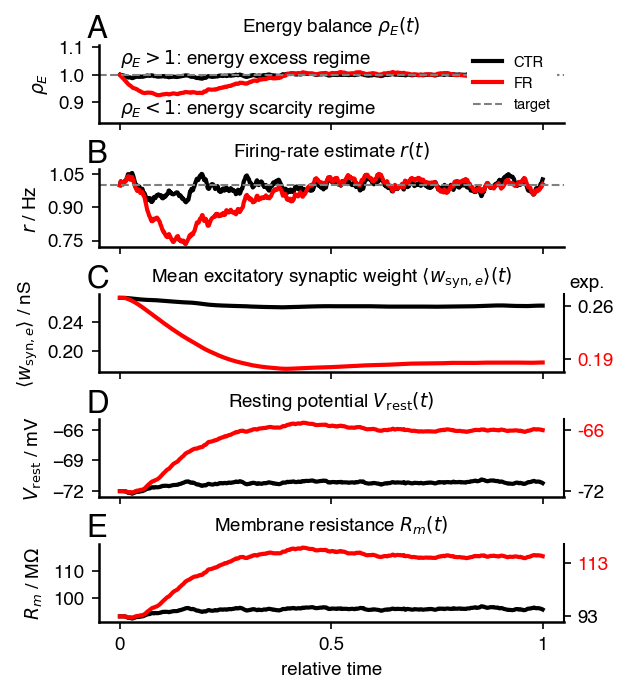

(<Figure size 600x750 with 8 Axes>,
 {'A': <Axes: label='A', title={'center': 'Energy balance $\\rho_E(t)$'}, ylabel='$\\rho_E$'>,
  'B': <Axes: label='B', title={'center': 'Firing-rate estimate $r(t)$'}, ylabel='$r$ / Hz'>,
  'C': <Axes: label='C', title={'center': 'Mean excitatory synaptic weight $\\langle w_{\\mathrm{syn},e} \\rangle(t)$'}, ylabel='$\\langle w_{\\mathrm{syn},e} \\rangle$ / nS'>,
  'D': <Axes: label='D', title={'center': 'Resting potential $V_{\\mathrm{rest}}(t)$'}, ylabel='$V_{\\mathrm{rest}}$ / mV'>,
  'E': <Axes: label='E', title={'center': 'Membrane resistance $R_m(t)$'}, xlabel='relative time', ylabel='$R_m$ / M$\\Omega$'>})

In [25]:
spike_times_post_CTR_PD, ISIs_CTR_PD, mean_ISI_CTR_PD, std_ISI_CTR_PD, var_ISI_CTR_PD, CV_ISI_CTR_PD = edIF.calculate_ISI_var_CV(spike_times_post_CTR_PD, T_min=500000)
spike_times_post_FR_PD, ISIs_FR_PD, mean_ISI_FR_PD, std_ISI_FR_PD, var_ISI_FR_PD, CV_ISI_FR_PD = edIF.calculate_ISI_var_CV(spike_times_post_FR_PD, T_min=500000)

print("CTR (equilibrated) spikes:", len(spike_times_post_CTR_PD), ", mean ISI:", round(mean_ISI_CTR_PD,0), "ms, std ISI:", round(std_ISI_CTR_PD,0), "ms, var ISI:", round(var_ISI_CTR_PD,0), "ms^2, CV_ISI:", round(CV_ISI_CTR_PD,2))
print("FR (equilibrated) spikes:", len(spike_times_post_FR_PD), ", mean ISI:", round(mean_ISI_FR_PD,0), "ms, std ISI:", round(std_ISI_FR_PD,0), "ms, var ISI:", round(var_ISI_FR_PD,0), "ms^2, CV_ISI:", round(CV_ISI_FR_PD,2))

ppf.fig_energy_IF_CTR_FR(time=[time_CTR_PD, time_FR_PD], rho_E_smooth=[rho_E_smooth_CTR_PD, rho_E_smooth_FR_PD], r_Ca_smooth=[r_Ca_dyn_smooth_CTR_PD, r_Ca_dyn_smooth_FR_PD], w_syn_e_dyn=[w_syn_e_dyn_CTR_PD, w_syn_e_dyn_FR_PD], V_rest_dyn=[V_rest_dyn_CTR_PD, V_rest_dyn_FR_PD], R_m_dyn=[R_m_dyn_CTR_PD, R_m_dyn_FR_PD], rho_E_target=rho_E_target, r_target=r_target, 
    #r_Ca_var_smooth=[data_CTR_PD["r_Ca_var"], data_FR_PD["r_Ca_var"]],
    #r_var_target=data_CTR_PD["r_var_target"],
    #var_CV_mode="var",
    #y_mode_V_rest="blocked",
    exp_w=[1, 1-0.28],
    exp_V_rest=[-72, -66],
    exp_R_m=[93, 113],
    downsample_factor=100,
    colors=['black', 'red'],
    fontsizes={'panelletterfontsize': 15},
    figsize=(4, 5),
    savename="3_results/fig_energy_IF_PPD_control")


## Energy-dependent IF: excitability-first control 

In [ ]:
# generating Fig. data
# define homogeneous synaptic input
T = 1000000 # in ms
N_syn, N_e, N_e_signal_ratio, N_i, rate_background_ratio, mu_rate_e, sigma_rate_e, mu_rate_i, sigma_rate_i, mu_weight_e, sigma_weight_e, mu_weight_i, sigma_weight_i = sif.synaptic_parameters(synaptic_scaling_mode='multiplicative')
w_e_0, w_i_0, spike_times_e, spike_times_i, r_e, r_i = sif.homogeneous_synaptic_input(T, N_e, N_i, mu_rate_e, sigma_rate_e, mu_rate_i, sigma_rate_i, mu_weight_e, sigma_weight_e, mu_weight_i, sigma_weight_i)

factor_w = 0.7
w_e = w_e_0 * 4 / 100 * factor_w
w_i = w_i_0 * 1 / 100 * factor_w

# simulate proportional energy-control and proportional-derivative rate-control
# load model parameters
C_m, V_rest, R_m, g_L, V_thresh, V_reset, Delta_T_ad, tau_w_ad, a_ad, b_ad, rate_window, tau_Ca, A_Ca, E_e, E_i, tau_e, tau_i, membrane_noise, rho_E_target, s_E, E_target_ATP, r_target, tau_r_smooth, tau_r_deriv, tau_E_smooth, dt_sim, dt_energy, tau_w_scale, tau_V_rest, tau_R_m, E_HK, V_Na, V_K, V_h, alpha_atp, e_c, A_R_m, A_overlap_AP, A_overlap_syn, d_axon, l_axon, d_soma, d_dendrite, l_dendrite, c_m_area, V_peak, N_boutons, E_glu_rec, E_Ca_ex = edIF.energy_dependent_sim_parameters(parameter_mode='CTR', membrane_noise=0.0, s_E=0.85)
# convert parameters to Brian2 units
T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, Delta_T_ad_b, tau_w_ad_b, a_ad_b, b_ad_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex = edIF.energy_parameters_brian(T, N_e, N_i, spike_times_e, spike_times_i, w_e, w_i, C_m, V_rest, R_m, g_L, V_thresh, V_reset, Delta_T_ad, tau_w_ad, a_ad, b_ad, rate_window, tau_Ca, A_Ca, E_e, E_i, tau_e, tau_i, membrane_noise, rho_E_target, s_E, E_target_ATP, r_target, tau_r_smooth, tau_r_deriv, tau_E_smooth, dt_sim, dt_energy, tau_w_scale, tau_V_rest, tau_R_m, E_HK, V_Na, V_K, V_h, alpha_atp, e_c, A_R_m, A_overlap_AP, A_overlap_syn, d_axon, l_axon, d_soma, d_dendrite, l_dendrite, c_m_area, V_peak, N_boutons, E_glu_rec, E_Ca_ex)

# CTR condition
s_E_CTR = 1.0
#time_CTR_PD_reverse, V_m_CTR_PD_reverse, spike_times_post_CTR_PD_reverse, rate_estimate_post_CTR_PD_reverse, I_syn_e_CTR_PD_reverse, I_syn_i_CTR_PD_reverse, g_e_CTR_PD_reverse, g_i_CTR_PD_reverse, E_cons_dyn_CTR_PD_reverse, E_prod_dyn_CTR_PD_reverse, rho_E_CTR_PD_reverse, rho_E_smooth_CTR_PD_reverse, rho_E_P_control_dyn_CTR_PD_reverse, r_Ca_CTR_PD_reverse, r_Ca_dyn_smooth_CTR_PD_reverse, dr_Ca_dyn_smooth_CTR_PD_reverse, r_PD_control_dyn_CTR_PD_reverse, w_syn_e_dyn_CTR_PD_reverse, V_rest_dyn_CTR_PD_reverse, R_m_dyn_CTR_PD_reverse = edIF.energy_dependent_LIF_reverse(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_CTR, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex)
time_CTR_PD_reverse, V_m_CTR_PD_reverse, w_ad_CTR_PD_reverse, spike_times_post_CTR_PD_reverse, rate_estimate_post_CTR_PD_reverse, I_syn_e_CTR_PD_reverse, I_syn_i_CTR_PD_reverse, g_e_CTR_PD_reverse, g_i_CTR_PD_reverse, E_cons_dyn_CTR_PD_reverse, E_prod_dyn_CTR_PD_reverse, rho_E_CTR_PD_reverse, rho_E_smooth_CTR_PD_reverse, rho_E_P_control_dyn_CTR_PD_reverse, r_Ca_CTR_PD_reverse, r_Ca_dyn_smooth_CTR_PD_reverse, dr_Ca_dyn_smooth_CTR_PD_reverse, r_PD_control_dyn_CTR_PD_reverse, w_syn_e_dyn_CTR_PD_reverse, V_rest_dyn_CTR_PD_reverse, R_m_dyn_CTR_PD_reverse = edIF.energy_dependent_AdExp_reverse(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, Delta_T_ad_b, tau_w_ad_b, a_ad_b, b_ad_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_CTR, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex)

# FR condition
s_E_FR = 0.85
#time_FR_PD_reverse, V_m_FR_PD_reverse, spike_times_post_FR_PD_reverse, rate_estimate_post_FR_PD_reverse, I_syn_e_FR_PD_reverse, I_syn_i_FR_PD_reverse, g_e_FR_PD_reverse, g_i_FR_PD_reverse, E_cons_dyn_FR_PD_reverse, E_prod_dyn_FR_PD_reverse, rho_E_FR_PD_reverse, rho_E_smooth_FR_PD_reverse, rho_E_P_control_dyn_FR_PD_reverse, r_Ca_FR_PD_reverse, r_Ca_dyn_smooth_FR_PD_reverse, dr_Ca_dyn_smooth_FR_PD_reverse, r_PD_control_dyn_FR_PD_reverse, w_syn_e_dyn_FR_PD_reverse, V_rest_dyn_FR_PD_reverse, R_m_dyn_FR_PD_reverse = edIF.energy_dependent_LIF_reverse(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_FR, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex)
time_FR_PD_reverse, V_m_FR_PD_reverse, w_ad_FR_PD_reverse, spike_times_post_FR_PD_reverse, rate_estimate_post_FR_PD_reverse, I_syn_e_FR_PD_reverse, I_syn_i_FR_PD_reverse, g_e_FR_PD_reverse, g_i_FR_PD_reverse, E_cons_dyn_FR_PD_reverse, E_prod_dyn_FR_PD_reverse, rho_E_FR_PD_reverse, rho_E_smooth_FR_PD_reverse, rho_E_P_control_dyn_FR_PD_reverse, r_Ca_FR_PD_reverse, r_Ca_dyn_smooth_FR_PD_reverse, dr_Ca_dyn_smooth_FR_PD_reverse, r_PD_control_dyn_FR_PD_reverse, w_syn_e_dyn_FR_PD_reverse, V_rest_dyn_FR_PD_reverse, R_m_dyn_FR_PD_reverse = edIF.energy_dependent_AdExp_reverse(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, Delta_T_ad_b, tau_w_ad_b, a_ad_b, b_ad_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_FR, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex)

# downsample data for smaller storage capacity
data_CTR_PD_reverse = {"time": time_CTR_PD_reverse, "V_m": V_m_CTR_PD_reverse, "w_ad": w_ad_CTR_PD_reverse, "spike_times_post": spike_times_post_CTR_PD_reverse, "rate_estimate_post": rate_estimate_post_CTR_PD_reverse, "I_syn_e": I_syn_e_CTR_PD_reverse, "I_syn_i": I_syn_i_CTR_PD_reverse, "g_e": g_e_CTR_PD_reverse, "g_i": g_i_CTR_PD_reverse, "E_cons_dyn": E_cons_dyn_CTR_PD_reverse, "E_prod_dyn": E_prod_dyn_CTR_PD_reverse, "rho_E": rho_E_CTR_PD_reverse, "rho_E_smooth": rho_E_smooth_CTR_PD_reverse, "rho_E_P_control_dyn": rho_E_P_control_dyn_CTR_PD_reverse, "r_Ca": r_Ca_CTR_PD_reverse, "r_Ca_smooth": r_Ca_dyn_smooth_CTR_PD_reverse, "dr_Ca_smooth": dr_Ca_dyn_smooth_CTR_PD_reverse, "r_PD_control_dyn": r_PD_control_dyn_CTR_PD_reverse, "w_syn_e_dyn": w_syn_e_dyn_CTR_PD_reverse, "V_rest_dyn": V_rest_dyn_CTR_PD_reverse, "R_m_dyn": R_m_dyn_CTR_PD_reverse, "rho_E_target": rho_E_target, "r_target": r_target_b/Hz, "s_E": s_E_CTR}
data_FR_PD_reverse = {"time": time_FR_PD_reverse, "V_m": V_m_FR_PD_reverse, "w_ad": w_ad_FR_PD_reverse, "spike_times_post": spike_times_post_FR_PD_reverse, "rate_estimate_post": rate_estimate_post_FR_PD_reverse, "I_syn_e": I_syn_e_FR_PD_reverse, "I_syn_i": I_syn_i_FR_PD_reverse, "g_e": g_e_FR_PD_reverse, "g_i": g_i_FR_PD_reverse, "E_cons_dyn": E_cons_dyn_FR_PD_reverse, "E_prod_dyn": E_prod_dyn_FR_PD_reverse, "rho_E": rho_E_FR_PD_reverse, "rho_E_smooth": rho_E_smooth_FR_PD_reverse, "rho_E_P_control_dyn": rho_E_P_control_dyn_FR_PD_reverse, "r_Ca": r_Ca_FR_PD_reverse, "r_Ca_smooth": r_Ca_dyn_smooth_FR_PD_reverse, "dr_Ca_smooth": dr_Ca_dyn_smooth_FR_PD_reverse, "r_PD_control_dyn": r_PD_control_dyn_FR_PD_reverse, "w_syn_e_dyn": w_syn_e_dyn_FR_PD_reverse, "V_rest_dyn": V_rest_dyn_FR_PD_reverse, "R_m_dyn": R_m_dyn_FR_PD_reverse, "rho_E_target": rho_E_target, "r_target": r_target_b/Hz, "s_E": s_E_FR}

data_CTR_PD_reverse_downsampled = edIF.downsample_energy_data_dict(data_CTR_PD_reverse, downsample_factor)
data_FR_PD_reverse_downsampled = edIF.downsample_energy_data_dict(data_FR_PD_reverse, downsample_factor)

#with open("../Data/energy_dependent_IF/energy_IF_CTR_FR_excitability_first_downsampled.pkl", "wb") as f:
#    pickle.dump({"CTR": data_CTR_PD_reverse_downsampled, "FR": data_FR_PD_reverse_downsampled, "downsample_factor": downsample_factor}, f)


In [28]:
# loading Fig. data
with open("../Data/energy_dependent_IF/energy_IF_CTR_FR_excitability_first_downsampled.pkl", "rb") as f:
    fig_data_reverse = pickle.load(f)

data_CTR_reverse = fig_data_reverse["CTR"]
data_FR_reverse = fig_data_reverse["FR"]

time_CTR_PD_reverse, rho_E_smooth_CTR_PD_reverse, r_Ca_dyn_smooth_CTR_PD_reverse, dr_Ca_dyn_smooth_CTR_PD_reverse, w_syn_e_dyn_CTR_PD_reverse, V_rest_dyn_CTR_PD_reverse, R_m_dyn_CTR_PD_reverse, E_cons_dyn_CTR_PD_reverse, rho_E_target, r_target, s_E_CTR = [data_CTR_reverse[k] for k in ["time", "rho_E_smooth", "r_Ca_smooth", "dr_Ca_smooth", "w_syn_e_dyn", "V_rest_dyn", "R_m_dyn", "E_cons_dyn", "rho_E_target", "r_target", "s_E"]]

time_FR_PD_reverse, rho_E_smooth_FR_PD_reverse, r_Ca_dyn_smooth_FR_PD_reverse, dr_Ca_dyn_smooth_FR_PD_reverse, w_syn_e_dyn_FR_PD_reverse, V_rest_dyn_FR_PD_reverse, R_m_dyn_FR_PD_reverse, E_cons_dyn_FR_PD_reverse, rho_E_target, r_target, s_E_FR = [data_FR_reverse[k] for k in ["time", "rho_E_smooth", "r_Ca_smooth", "dr_Ca_smooth", "w_syn_e_dyn", "V_rest_dyn", "R_m_dyn", "E_cons_dyn", "rho_E_target", "r_target", "s_E"]]


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


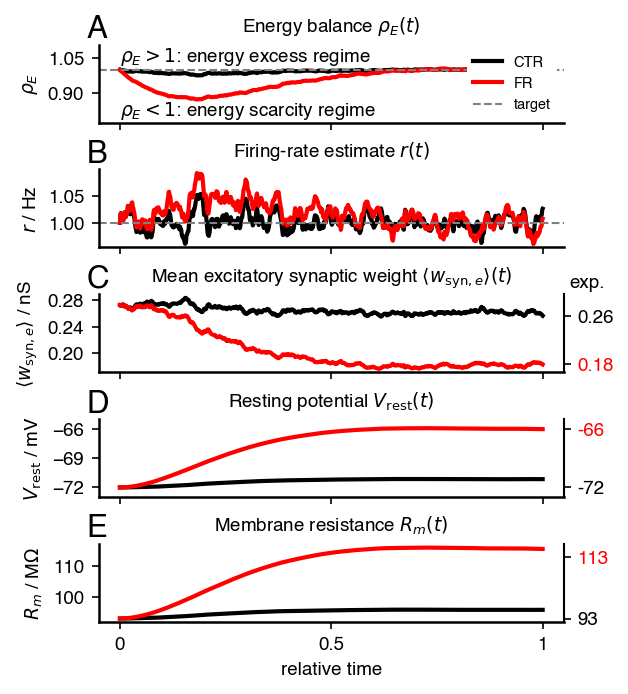

(<Figure size 600x750 with 8 Axes>,
 {'A': <Axes: label='A', title={'center': 'Energy balance $\\rho_E(t)$'}, ylabel='$\\rho_E$'>,
  'B': <Axes: label='B', title={'center': 'Firing-rate estimate $r(t)$'}, ylabel='$r$ / Hz'>,
  'C': <Axes: label='C', title={'center': 'Mean excitatory synaptic weight $\\langle w_{\\mathrm{syn},e} \\rangle(t)$'}, ylabel='$\\langle w_{\\mathrm{syn},e} \\rangle$ / nS'>,
  'D': <Axes: label='D', title={'center': 'Resting potential $V_{\\mathrm{rest}}(t)$'}, ylabel='$V_{\\mathrm{rest}}$ / mV'>,
  'E': <Axes: label='E', title={'center': 'Membrane resistance $R_m(t)$'}, xlabel='relative time', ylabel='$R_m$ / M$\\Omega$'>})

In [30]:
# plotting Fig. data
ppf.fig_energy_IF_CTR_FR(time=[time_CTR_PD_reverse, time_FR_PD_reverse], rho_E_smooth=[rho_E_smooth_CTR_PD_reverse, rho_E_smooth_FR_PD_reverse], r_Ca_smooth=[r_Ca_dyn_smooth_CTR_PD_reverse, r_Ca_dyn_smooth_FR_PD_reverse], w_syn_e_dyn=[w_syn_e_dyn_CTR_PD_reverse, w_syn_e_dyn_FR_PD_reverse], V_rest_dyn=[V_rest_dyn_CTR_PD_reverse, V_rest_dyn_FR_PD_reverse], R_m_dyn=[R_m_dyn_CTR_PD_reverse, R_m_dyn_FR_PD_reverse], rho_E_target=rho_E_target, r_target=r_target,
    #r_Ca_var_smooth=[data_CTR["r_Ca_var"], data_FR["r_Ca_var"]],
    #r_var_target=data_CTR["r_var_target"],
    #var_CV_mode="var",
    y_mode_V_rest = "blocked",
    exp_w = [1,1-0.28],
    exp_V_rest = [-72,-66],
    exp_R_m = [93,113],
    downsample_factor=100,
    colors=['black', 'red'], fontsizes={'panelletterfontsize': 15}, figsize=(4,5), savename="3_results/fig_energy_IF_PPD_control_reverse")

## Simulations favor synapse-first over excitability-first model

In [ ]:
# generate Fig. data
with open("../Data/energy_dependent_IF/energy_IF_CTR_FR_PPD_synapse_first_downsampled.pkl", "rb") as f:
    data_synapse_first = pickle.load(f)

data_FR_synapse_first = data_synapse_first["FR"]
time_FR_synapse_first, w_syn_e_dyn_FR_synapse_first, V_rest_dyn_FR_synapse_first, R_m_dyn_FR_synapse_first, E_cons_dyn_FR_synapse_first = [data_FR_synapse_first[k] for k in ["time", "w_syn_e_dyn", "V_rest_dyn", "R_m_dyn", "E_cons_dyn"]]

with open("../Data/energy_dependent_IF/energy_IF_CTR_FR_excitability_first_downsampled.pkl", "rb") as f:
    data_excitability_first = pickle.load(f)

data_FR_excitability_first = data_excitability_first["FR"]
time_FR_excitability_first, w_syn_e_dyn_FR_excitability_first, V_rest_dyn_FR_excitability_first, R_m_dyn_FR_excitability_first, E_cons_dyn_FR_excitability_first = [data_FR_excitability_first[k] for k in ["time", "w_syn_e_dyn", "V_rest_dyn", "R_m_dyn", "E_cons_dyn"]]

t_end=350
n_timepoints=14
w_scale_target=100
trajectory_FR_synapse_first = edIF.get_FR_trajectory_values_at_timepoints(time_FR_synapse_first, w_syn_e_dyn_FR_synapse_first, V_rest_dyn_FR_synapse_first, R_m_dyn_FR_synapse_first, t_end, n_timepoints, w_scale_target)
trajectory_FR_excitability_first = edIF.get_FR_trajectory_values_at_timepoints(time_FR_excitability_first, w_syn_e_dyn_FR_excitability_first, V_rest_dyn_FR_excitability_first, R_m_dyn_FR_excitability_first, t_end, n_timepoints, w_scale_target)

number_single_runs=1000
results_FR_synapse_first_LIF, results_FR_synapse_first_AdExp = sf.multiple_FR_trajectory_run(number_single_runs=number_single_runs, FR_trajectory_points=trajectory_FR_synapse_first, model_mode='AdExp', membrane_noise=1.0, synaptic_scaling_mode='multiplicative', savename='FR_trajectory_synapse_first')
results_FR_excitability_first_LIF, results_FR_excitability_first_AdExp = sf.multiple_FR_trajectory_run(number_single_runs=number_single_runs, FR_trajectory_points=trajectory_FR_excitability_first, model_mode='AdExp', membrane_noise=1.0, synaptic_scaling_mode='multiplicative', savename='FR_trajectory_excitability_first')

results_mean_FR_trajectory_synapse_first = edIF.mean_FR_trajectory_results_over_runs(results_FR_synapse_first_AdExp)
results_mean_FR_trajectory_excitability_first = edIF.mean_FR_trajectory_results_over_runs(results_FR_excitability_first_AdExp)

with open('../Data/energy_dependent_IF/results_mean_FR_trajectory_synapse_first.pkl', 'wb') as f:
    pickle.dump(results_mean_FR_trajectory_synapse_first, f)
with open('../Data/energy_dependent_IF/results_mean_FR_trajectory_excitability_first.pkl', 'wb') as f:
    pickle.dump(results_mean_FR_trajectory_excitability_first, f)


import time as tp

t_start = tp.perf_counter()
print(f"Simulated data in {tp.perf_counter() - t_start:.2f} s")


In [10]:
# loading Fig. data
with open("../Data/energy_dependent_IF/energy_IF_CTR_FR_PPD_synapse_first_downsampled.pkl", "rb") as f:
    data_synapse_first = pickle.load(f)

data_FR_synapse_first = data_synapse_first["FR"]
time_FR_synapse_first, w_syn_e_dyn_FR_synapse_first, V_rest_dyn_FR_synapse_first, R_m_dyn_FR_synapse_first, E_cons_dyn_FR_synapse_first = [data_FR_synapse_first[k] for k in ["time", "w_syn_e_dyn", "V_rest_dyn", "R_m_dyn", "E_cons_dyn"]]

with open("../Data/energy_dependent_IF/energy_IF_CTR_FR_excitability_first_downsampled.pkl", "rb") as f:
    data_excitability_first = pickle.load(f)

data_FR_excitability_first = data_excitability_first["FR"]
time_FR_excitability_first, w_syn_e_dyn_FR_excitability_first, V_rest_dyn_FR_excitability_first, R_m_dyn_FR_excitability_first, E_cons_dyn_FR_excitability_first = [data_FR_excitability_first[k] for k in ["time", "w_syn_e_dyn", "V_rest_dyn", "R_m_dyn", "E_cons_dyn"]]

with open('../Data/energy_dependent_IF/results_FR_synapse_first_AdExp.pkl', 'rb') as f:
    results_FR_trajectory_synapse_first = pickle.load(f)
with open('../Data/energy_dependent_IF/results_mean_FR_trajectory_synapse_first.pkl', 'rb') as f:
    results_mean_FR_trajectory_synapse_first = pickle.load(f)

with open('../Data/energy_dependent_IF/results_FR_excitability_first_AdExp.pkl', 'rb') as f:
    results_FR_trajectory_excitability_first = pickle.load(f)
with open('../Data/energy_dependent_IF/results_mean_FR_trajectory_excitability_first.pkl', 'rb') as f:
    results_mean_FR_trajectory_excitability_first = pickle.load(f)


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


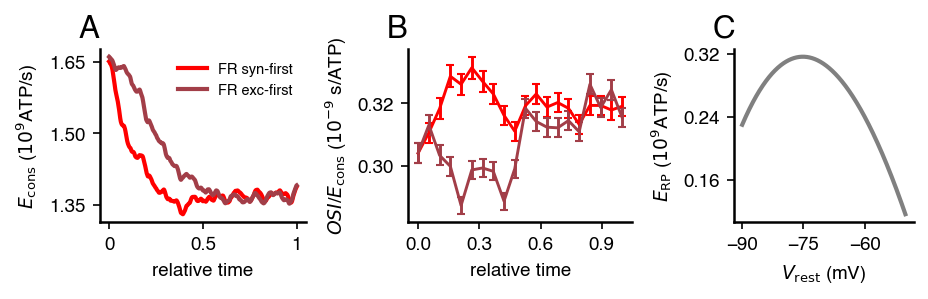

In [76]:

import importlib 
importlib.reload(pf)
importlib.reload(ppf)
importlib.reload(edIF)
fig, ax = ppf.fig_synapse_vs_excitability_first(
    time_FR_PD=time_FR_synapse_first,
    time_FR_PD_reverse=time_FR_excitability_first,
    E_cons_dyn_FR_PD=E_cons_dyn_FR_synapse_first, 
    E_cons_dyn_FR_PD_reverse=E_cons_dyn_FR_excitability_first,
    results_mean_FR_trajectory_synapse_first=results_mean_FR_trajectory_synapse_first, 
    results_mean_FR_trajectory_excitability_first=results_mean_FR_trajectory_excitability_first,
    results_FR_synapse_first=results_FR_trajectory_synapse_first,
    results_FR_excitability_first=results_FR_trajectory_excitability_first,
    E_target_ATP=1.6,
    downsample_factor=100,
    colors=[color_FR, color_FR_excitability_first],
    labels=['FR syn-first', 'FR exc-first'],
    figsize=(7,1.5), 
    savename_mode=True)


## Energy-dependent IF: variance control 

In [ ]:
# generating Fig. data

# define homogeneous synaptic input
T = 1000000 # in ms
N_syn, N_e, N_e_signal_ratio, N_i, rate_background_ratio, mu_rate_e, sigma_rate_e, mu_rate_i, sigma_rate_i, mu_weight_e, sigma_weight_e, mu_weight_i, sigma_weight_i = sif.synaptic_parameters(synaptic_scaling_mode='multiplicative')
w_e_0, w_i_0, spike_times_e, spike_times_i, r_e, r_i = sif.homogeneous_synaptic_input(T, N_e, N_i, mu_rate_e, sigma_rate_e, mu_rate_i, sigma_rate_i, mu_weight_e, sigma_weight_e, mu_weight_i, sigma_weight_i)

factor_w = 0.7
w_e = w_e_0 * 4 / 100 * factor_w
w_i = w_i_0 * 1 / 100 * factor_w

# simulate proportional energy-control and proportional-derivative rate-control
# load model parameters
C_m, V_rest, R_m, g_L, V_thresh, V_reset, Delta_T_ad, tau_w_ad, a_ad, b_ad, rate_window, tau_Ca, A_Ca, E_e, E_i, tau_e, tau_i, membrane_noise, rho_E_target, s_E, E_target_ATP, r_target, tau_r_smooth, tau_r_deriv, tau_E_smooth, dt_sim, dt_energy, tau_w_scale, tau_V_rest, tau_R_m, E_HK, V_Na, V_K, V_h, alpha_atp, e_c, A_R_m, A_overlap_AP, A_overlap_syn, d_axon, l_axon, d_soma, d_dendrite, l_dendrite, c_m_area, V_peak, N_boutons, E_glu_rec, E_Ca_ex = edIF.energy_dependent_sim_parameters(parameter_mode='CTR', membrane_noise=0.0, s_E=0.85)
# convert parameters to Brian2 units
T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, Delta_T_ad_b, tau_w_ad_b, a_ad_b, b_ad_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex = edIF.energy_parameters_brian(T, N_e, N_i, spike_times_e, spike_times_i, w_e, w_i, C_m, V_rest, R_m, g_L, V_thresh, V_reset, Delta_T_ad, tau_w_ad, a_ad, b_ad, rate_window, tau_Ca, A_Ca, E_e, E_i, tau_e, tau_i, membrane_noise, rho_E_target, s_E, E_target_ATP, r_target, tau_r_smooth, tau_r_deriv, tau_E_smooth, dt_sim, dt_energy, tau_w_scale, tau_V_rest, tau_R_m, E_HK, V_Na, V_K, V_h, alpha_atp, e_c, A_R_m, A_overlap_AP, A_overlap_syn, d_axon, l_axon, d_soma, d_dendrite, l_dendrite, c_m_area, V_peak, N_boutons, E_glu_rec, E_Ca_ex)

# define variance-control parameters
r_Ca_var_target = 0.29 # Hz^2
r_Ca_var_target_b = r_Ca_var_target*Hz**2
tau_dr_smooth = 100 # ms
tau_dr_smooth_b = tau_dr_smooth*ms

# CTR condition 
s_E_CTR = 1.0 
time_CTR_var, V_m_CTR_var, w_ad_CTR_var, spike_times_post_CTR_var, rate_estimate_post_CTR_var, I_syn_e_CTR_var, I_syn_i_CTR_var, g_e_CTR_var, g_i_CTR_var, E_cons_dyn_CTR_var, E_prod_dyn_CTR_var, rho_E_CTR_var, rho_E_smooth_CTR_var, rho_E_P_control_dyn_CTR_var, r_Ca_CTR_var, r_Ca_dyn_smooth_CTR_var, dr_Ca_dyn_smooth_CTR_var, r_PD_control_dyn_CTR_var, w_syn_e_dyn_CTR_var, V_rest_dyn_CTR_var, R_m_dyn_CTR_var, r_Ca2_dyn_smooth_CTR_var, r_Ca_var_dyn_CTR_var, r_Ca_var_control_dyn_CTR_var = edIF.energy_dependent_AdExp_variance(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, Delta_T_ad_b, tau_w_ad_b, a_ad_b, b_ad_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_CTR, E_target_ATP_b, r_target_b, r_Ca_var_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_dr_smooth_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex) 

# FR condition 
s_E_FR = 0.85 
time_FR_var, V_m_FR_var, w_ad_FR_var, spike_times_post_FR_var, rate_estimate_post_FR_var, I_syn_e_FR_var, I_syn_i_FR_var, g_e_FR_var, g_i_FR_var, E_cons_dyn_FR_var, E_prod_dyn_FR_var, rho_E_FR_var, rho_E_smooth_FR_var, rho_E_P_control_dyn_FR_var, r_Ca_FR_var, r_Ca_dyn_smooth_FR_var, dr_Ca_dyn_smooth_FR_var, r_PD_control_dyn_FR_var, w_syn_e_dyn_FR_var, V_rest_dyn_FR_var, R_m_dyn_FR_var, r_Ca2_dyn_smooth_FR_var, r_Ca_var_dyn_FR_var, r_Ca_var_control_dyn_FR_var = edIF.energy_dependent_AdExp_variance(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, Delta_T_ad_b, tau_w_ad_b, a_ad_b, b_ad_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_FR, E_target_ATP_b, r_target_b, r_Ca_var_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_dr_smooth_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex)

# downsample data for smaller storage capacity
downsample_factor = 100
data_CTR_var = {"time": time_CTR_var, "V_m": V_m_CTR_var, "w_ad": w_ad_CTR_var, "spike_times_post": spike_times_post_CTR_var, "rate_estimate_post": rate_estimate_post_CTR_var, "I_syn_e": I_syn_e_CTR_var, "I_syn_i": I_syn_i_CTR_var, "g_e": g_e_CTR_var, "g_i": g_i_CTR_var, "E_cons_dyn": E_cons_dyn_CTR_var, "E_prod_dyn": E_prod_dyn_CTR_var, "rho_E": rho_E_CTR_var, "rho_E_smooth": rho_E_smooth_CTR_var, "rho_E_P_control_dyn": rho_E_P_control_dyn_CTR_var, "r_Ca": r_Ca_CTR_var, "r_Ca_smooth": r_Ca_dyn_smooth_CTR_var, "dr_Ca_smooth": dr_Ca_dyn_smooth_CTR_var, "r_PD_control_dyn": r_PD_control_dyn_CTR_var, "w_syn_e_dyn": w_syn_e_dyn_CTR_var, "V_rest_dyn": V_rest_dyn_CTR_var, "R_m_dyn": R_m_dyn_CTR_var, "r_Ca2_smooth": r_Ca2_dyn_smooth_CTR_var, "r_Ca_var": r_Ca_var_dyn_CTR_var, "r_Ca_var_control_dyn": r_Ca_var_control_dyn_CTR_var, "rho_E_target": rho_E_target, "r_target": r_target_b/Hz, "r_Ca_var_target": r_Ca_var_target_b/Hz**2, "s_E": s_E_CTR}
data_FR_var = {"time": time_FR_var, "V_m": V_m_FR_var, "w_ad": w_ad_FR_var, "spike_times_post": spike_times_post_FR_var, "rate_estimate_post": rate_estimate_post_FR_var, "I_syn_e": I_syn_e_FR_var, "I_syn_i": I_syn_i_FR_var, "g_e": g_e_FR_var, "g_i": g_i_FR_var, "E_cons_dyn": E_cons_dyn_FR_var, "E_prod_dyn": E_prod_dyn_FR_var, "rho_E": rho_E_FR_var, "rho_E_smooth": rho_E_smooth_FR_var, "rho_E_P_control_dyn": rho_E_P_control_dyn_FR_var, "r_Ca": r_Ca_FR_var, "r_Ca_smooth": r_Ca_dyn_smooth_FR_var, "dr_Ca_smooth": dr_Ca_dyn_smooth_FR_var, "r_PD_control_dyn": r_PD_control_dyn_FR_var, "w_syn_e_dyn": w_syn_e_dyn_FR_var, "V_rest_dyn": V_rest_dyn_FR_var, "R_m_dyn": R_m_dyn_FR_var, "r_Ca2_smooth": r_Ca2_dyn_smooth_FR_var, "r_Ca_var": r_Ca_var_dyn_FR_var, "r_Ca_var_control_dyn": r_Ca_var_control_dyn_FR_var, "rho_E_target": rho_E_target, "r_target": r_target_b/Hz, "r_Ca_var_target": r_Ca_var_target_b/Hz**2, "s_E": s_E_FR}
data_CTR_var_downsampled = edIF.downsample_energy_data_dict(data_CTR_var, downsample_factor)
data_FR_var_downsampled = edIF.downsample_energy_data_dict(data_FR_var, downsample_factor)

#with open("../Data/energy_dependent_IF/energy_IF_CTR_FR_PPD_variance_downsampled.pkl", "wb") as f:
#    pickle.dump({"CTR": data_CTR_var_downsampled, "FR": data_FR_var_downsampled, "downsample_factor": downsample_factor}, f)
    

In [39]:
# loading Fig.
with open("../Data/energy_dependent_IF/energy_IF_CTR_FR_PPD_variance_downsampled.pkl", "rb") as f:
    fig_data_var = pickle.load(f)

data_CTR_var = fig_data_var["CTR"]
data_FR_var = fig_data_var["FR"]
#time_CTR_var_LIF, rho_E_smooth_CTR_var_LIF, r_Ca_dyn_smooth_CTR_var_LIF, dr_Ca_dyn_smooth_CTR_var_LIF, w_syn_e_dyn_CTR_var_LIF, V_rest_dyn_CTR_var_LIF, R_m_dyn_CTR_var_LIF, r_Ca_var_dyn_CTR_var_LIF, rho_E_target, r_target, r_Ca_var_target, s_E_CTR = [data_CTR_var_LIF[k] for k in ["time", "rho_E_smooth", "r_Ca_smooth", "dr_Ca_smooth", "w_syn_e_dyn", "V_rest_dyn", "R_m_dyn", "r_Ca_var", "rho_E_target", "r_target", "r_Ca_var_target", "s_E"]]
time_CTR_var, rho_E_smooth_CTR_var, r_Ca_dyn_smooth_CTR_var, dr_Ca_dyn_smooth_CTR_var, w_syn_e_dyn_CTR_var, V_rest_dyn_CTR_var, R_m_dyn_CTR_var, r_Ca_var_dyn_CTR_var, rho_E_target, r_target, r_Ca_var_target, s_E_CTR = [data_CTR_var[k] for k in ["time", "rho_E_smooth", "r_Ca_smooth", "dr_Ca_smooth", "w_syn_e_dyn", "V_rest_dyn", "R_m_dyn", "r_Ca_var", "rho_E_target", "r_target", "r_Ca_var_target", "s_E"]]

#time_FR_var_LIF, rho_E_smooth_FR_var_LIF, r_Ca_dyn_smooth_FR_var_LIF, dr_Ca_dyn_smooth_FR_var_LIF, w_syn_e_dyn_FR_var_LIF, V_rest_dyn_FR_var_LIF, R_m_dyn_FR_var_LIF, r_Ca_var_dyn_FR_var_LIF, rho_E_target, r_target, r_Ca_var_target, s_E_FR = [data_FR_var_LIF[k] for k in ["time", "rho_E_smooth", "r_Ca_smooth", "dr_Ca_smooth", "w_syn_e_dyn", "V_rest_dyn", "R_m_dyn", "r_Ca_var", "rho_E_target", "r_target", "r_Ca_var_target", "s_E"]]
time_FR_var, rho_E_smooth_FR_var, r_Ca_dyn_smooth_FR_var, dr_Ca_dyn_smooth_FR_var, w_syn_e_dyn_FR_var, V_rest_dyn_FR_var, R_m_dyn_FR_var, r_Ca_var_dyn_FR_var, rho_E_target, r_target, r_Ca_var_target, s_E_FR = [data_FR_var[k] for k in ["time", "rho_E_smooth", "r_Ca_smooth", "dr_Ca_smooth", "w_syn_e_dyn", "V_rest_dyn", "R_m_dyn", "r_Ca_var", "rho_E_target", "r_target", "r_Ca_var_target", "s_E"]]



1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


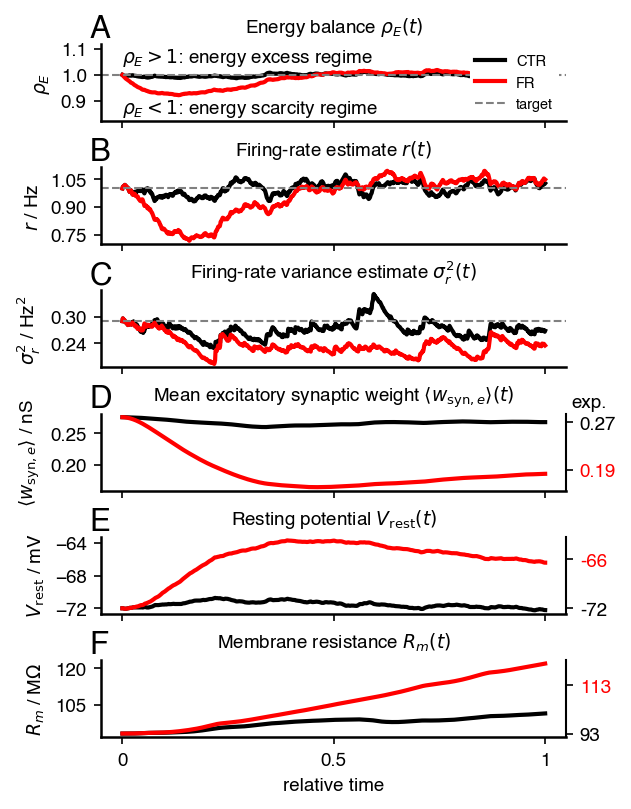

(<Figure size 600x900 with 9 Axes>,
 {'A': <Axes: label='A', title={'center': 'Energy balance $\\rho_E(t)$'}, ylabel='$\\rho_E$'>,
  'B': <Axes: label='B', title={'center': 'Firing-rate estimate $r(t)$'}, ylabel='$r$ / Hz'>,
  'C': <Axes: label='C', title={'center': 'Firing-rate variance estimate $\\sigma^2_{r}(t)$'}, ylabel='$\\sigma^2_{r}$ / Hz$^2$'>,
  'D': <Axes: label='D', title={'center': 'Mean excitatory synaptic weight $\\langle w_{\\mathrm{syn},e} \\rangle(t)$'}, ylabel='$\\langle w_{\\mathrm{syn},e} \\rangle$ / nS'>,
  'E': <Axes: label='E', title={'center': 'Resting potential $V_{\\mathrm{rest}}(t)$'}, ylabel='$V_{\\mathrm{rest}}$ / mV'>,
  'F': <Axes: label='F', title={'center': 'Membrane resistance $R_m(t)$'}, xlabel='relative time', ylabel='$R_m$ / M$\\Omega$'>})

In [41]:
# plot Fig. data

ppf.fig_energy_IF_CTR_FR(time=[time_CTR_var, time_FR_var], rho_E_smooth=[rho_E_smooth_CTR_var, rho_E_smooth_FR_var], r_Ca_smooth=[r_Ca_dyn_smooth_CTR_var, r_Ca_dyn_smooth_FR_var], w_syn_e_dyn=[w_syn_e_dyn_CTR_var, w_syn_e_dyn_FR_var], V_rest_dyn=[V_rest_dyn_CTR_var, V_rest_dyn_FR_var], R_m_dyn=[R_m_dyn_CTR_var, R_m_dyn_FR_var], rho_E_target=rho_E_target, r_target=r_target,
    r_Ca_var_smooth=[r_Ca_var_dyn_CTR_var, r_Ca_var_dyn_FR_var],
    r_var_target=r_Ca_var_target,
    var_CV_mode="var",
    #y_mode_V_rest = "blocked",
    exp_w=[1, 1-0.28],
    exp_V_rest=[-72, -66],
    exp_R_m=[93, 113],
    downsample_factor=100,
    colors=['black', 'red'],
    fontsizes={'panelletterfontsize': 15},
    figsize=(4, 5),
    savename="5_supplements/fig_energy_IF_PPD_control_variance")


## Data analysis in vivo natural scenes

In [ ]:
# generate Fig. data
df_cell = dafPns.run_movie_current_clamp_analysis(filename="MovieCurrentClampTraces/MovieCurrentClampTraces.mat", duration_s=42, prominence=42, distance_ms=10, pre_grey_s=(0, 4), movie_s=(4, 39), post_grey_s=(39, 42), condition_map=None, metrics_to_compare=None)
firing_statistics = dafPns.save_firing_statistics_to_pickle(df_cell, save_path="../Data/Padamsey_data_analysis/firing_statistics_movie.pkl") #"firing_statistics_movie.pkl")


In [43]:
# loading Fig. data
with open("../Data/Padamsey_data_analysis/firing_statistics_movie.pkl", "rb") as f:
    firing_statistics = pickle.load(f)

firing_rate_movie_CTR = firing_statistics["firing_rate_movie_CTR"]
firing_rate_movie_FR = firing_statistics["firing_rate_movie_FR"]

ISI_var_movie_CTR = firing_statistics["ISI_var_movie_CTR"]
ISI_var_movie_FR = firing_statistics["ISI_var_movie_FR"]

CV_ISI_movie_CTR = firing_statistics["CV_ISI_movie_CTR"]
CV_ISI_movie_FR = firing_statistics["CV_ISI_movie_FR"]

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


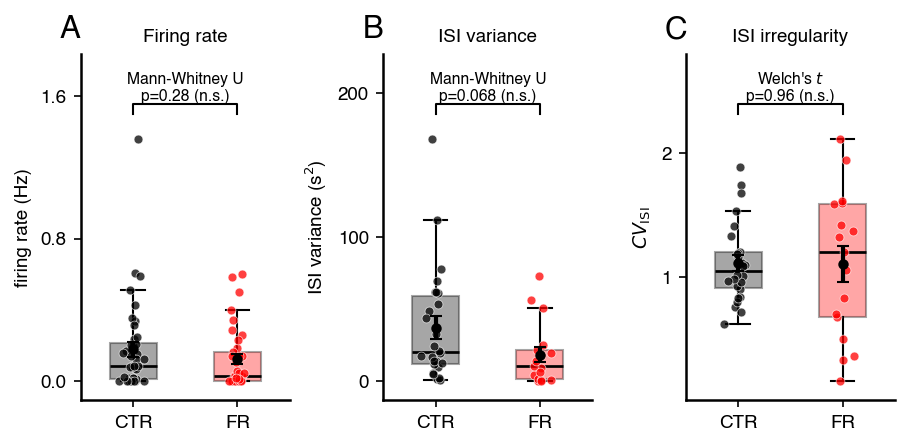

In [51]:
# plot Fig. data
ppf.fig_natural_scenes(firing_statistics, colors=['black', 'red'], fontsizes={'panelletterfontsize': 15}, figsize=(7,3), savename_mode=True);


## Energy-dependent IF: proportional control 

In [ ]:
# generate Fig. data

# define homogeneous synaptic input
T = 1000000 # in ms
N_syn, N_e, N_e_signal_ratio, N_i, rate_background_ratio, mu_rate_e, sigma_rate_e, mu_rate_i, sigma_rate_i, mu_weight_e, sigma_weight_e, mu_weight_i, sigma_weight_i = sif.synaptic_parameters(synaptic_scaling_mode='multiplicative')
w_e_0, w_i_0, spike_times_e, spike_times_i, r_e, r_i = sif.homogeneous_synaptic_input(T, N_e, N_i, mu_rate_e, sigma_rate_e, mu_rate_i, sigma_rate_i, mu_weight_e, sigma_weight_e, mu_weight_i, sigma_weight_i)

factor_w = 0.7
w_e = w_e_0 * 4 / 100 * factor_w
w_i = w_i_0 * 1 / 100 * factor_w

# simulate proportional energy-control and proportional-derivative rate-control
# load model parameters
C_m, V_rest, R_m, g_L, V_thresh, V_reset, Delta_T_ad, tau_w_ad, a_ad, b_ad, rate_window, tau_Ca, A_Ca, E_e, E_i, tau_e, tau_i, membrane_noise, rho_E_target, s_E, E_target_ATP, r_target, tau_r_smooth, tau_r_deriv, tau_E_smooth, dt_sim, dt_energy, tau_w_scale, tau_V_rest, tau_R_m, E_HK, V_Na, V_K, V_h, alpha_atp, e_c, A_R_m, A_overlap_AP, A_overlap_syn, d_axon, l_axon, d_soma, d_dendrite, l_dendrite, c_m_area, V_peak, N_boutons, E_glu_rec, E_Ca_ex = edIF.energy_dependent_sim_parameters(parameter_mode='CTR', membrane_noise=0.0, s_E=0.85)
# convert parameters to Brian2 units
T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, Delta_T_ad_b, tau_w_ad_b, a_ad_b, b_ad_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex = edIF.energy_parameters_brian(T, N_e, N_i, spike_times_e, spike_times_i, w_e, w_i, C_m, V_rest, R_m, g_L, V_thresh, V_reset, Delta_T_ad, tau_w_ad, a_ad, b_ad, rate_window, tau_Ca, A_Ca, E_e, E_i, tau_e, tau_i, membrane_noise, rho_E_target, s_E, E_target_ATP, r_target, tau_r_smooth, tau_r_deriv, tau_E_smooth, dt_sim, dt_energy, tau_w_scale, tau_V_rest, tau_R_m, E_HK, V_Na, V_K, V_h, alpha_atp, e_c, A_R_m, A_overlap_AP, A_overlap_syn, d_axon, l_axon, d_soma, d_dendrite, l_dendrite, c_m_area, V_peak, N_boutons, E_glu_rec, E_Ca_ex)

# block derivative control by slow dynamics
tau_r_deriv_b = 0.0000001*ms

# CTR condition
s_E_CTR = 1.0
#time_CTR_P, V_m_CTR_P, spike_times_post_CTR_P, rate_estimate_post_CTR_P, I_syn_e_CTR_P, I_syn_i_CTR_P, g_e_CTR_P, g_i_CTR_P, E_cons_dyn_CTR_P, E_prod_dyn_CTR_P, rho_E_CTR_P, rho_E_smooth_CTR_P, rho_E_P_control_dyn_CTR_P, r_Ca_CTR_P, r_Ca_dyn_smooth_CTR_P, dr_Ca_dyn_smooth_CTR_P, r_P_control_dyn_CTR_P, w_syn_e_dyn_CTR_P, V_rest_dyn_CTR_P, R_m_dyn_CTR_P = edIF.energy_dependent_LIF_P_energy_PD_rate_control(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_CTR, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex)
time_CTR_P, V_m_CTR_P, w_ad_CTR_P, spike_times_post_CTR_P, rate_estimate_post_CTR_P, I_syn_e_CTR_P, I_syn_i_CTR_P, g_e_CTR_P, g_i_CTR_P, E_cons_dyn_CTR_P, E_prod_dyn_CTR_P, rho_E_CTR_P, rho_E_smooth_CTR_P, rho_E_P_control_dyn_CTR_P, r_Ca_CTR_P, r_Ca_dyn_smooth_CTR_P, dr_Ca_dyn_smooth_CTR_P, r_P_control_dyn_CTR_P, w_syn_e_dyn_CTR_P, V_rest_dyn_CTR_P, R_m_dyn_CTR_P = edIF.energy_dependent_AdExp_P_energy_PD_rate_control(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, Delta_T_ad_b, tau_w_ad_b, a_ad_b, b_ad_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_CTR, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex)

# FR condition
s_E_FR = 0.85
#time_FR_P, V_m_FR_P, spike_times_post_FR_P, rate_estimate_post_FR_P, I_syn_e_FR_P, I_syn_i_FR_P, g_e_FR_P, g_i_FR_P, E_cons_dyn_FR_P, E_prod_dyn_FR_P, rho_E_FR_P, rho_E_smooth_FR_P, rho_E_P_control_dyn_FR_P, r_Ca_FR_P, r_Ca_dyn_smooth_FR_P, dr_Ca_dyn_smooth_FR_P, r_P_control_dyn_FR_P, w_syn_e_dyn_FR_P, V_rest_dyn_FR_P, R_m_dyn_FR_P = edIF.energy_dependent_LIF_P_energy_PD_rate_control(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_FR, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex)
time_FR_P, V_m_FR_P, w_ad_FR_P, spike_times_post_FR_P, rate_estimate_post_FR_P, I_syn_e_FR_P, I_syn_i_FR_P, g_e_FR_P, g_i_FR_P, E_cons_dyn_FR_P, E_prod_dyn_FR_P, rho_E_FR_P, rho_E_smooth_FR_P, rho_E_P_control_dyn_FR_P, r_Ca_FR_P, r_Ca_dyn_smooth_FR_P, dr_Ca_dyn_smooth_FR_P, r_P_control_dyn_FR_P, w_syn_e_dyn_FR_P, V_rest_dyn_FR_P, R_m_dyn_FR_P = edIF.energy_dependent_AdExp_P_energy_PD_rate_control(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, Delta_T_ad_b, tau_w_ad_b, a_ad_b, b_ad_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_FR, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex)

# downsample data for smaller storage capacity
downsample_factor = 100
data_CTR_P = {"time": time_CTR_P, "V_m": V_m_CTR_P, "w_ad": w_ad_CTR_P, "spike_times_post": spike_times_post_CTR_P, "rate_estimate_post": rate_estimate_post_CTR_P, "I_syn_e": I_syn_e_CTR_P, "I_syn_i": I_syn_i_CTR_P, "g_e": g_e_CTR_P, "g_i": g_i_CTR_P, "E_cons_dyn": E_cons_dyn_CTR_P, "E_prod_dyn": E_prod_dyn_CTR_P, "rho_E": rho_E_CTR_P, "rho_E_smooth": rho_E_smooth_CTR_P, "rho_E_P_control_dyn": rho_E_P_control_dyn_CTR_P, "r_Ca": r_Ca_CTR_P, "r_Ca_smooth": r_Ca_dyn_smooth_CTR_P, "dr_Ca_smooth": dr_Ca_dyn_smooth_CTR_P, "r_P_control_dyn": r_P_control_dyn_CTR_P, "w_syn_e_dyn": w_syn_e_dyn_CTR_P, "V_rest_dyn": V_rest_dyn_CTR_P, "R_m_dyn": R_m_dyn_CTR_P, "rho_E_target": rho_E_target, "r_target": r_target_b/Hz, "s_E": s_E_CTR}
data_FR_P = {"time": time_FR_P, "V_m": V_m_FR_P, "w_ad": w_ad_FR_P, "spike_times_post": spike_times_post_FR_P, "rate_estimate_post": rate_estimate_post_FR_P, "I_syn_e": I_syn_e_FR_P, "I_syn_i": I_syn_i_FR_P, "g_e": g_e_FR_P, "g_i": g_i_FR_P, "E_cons_dyn": E_cons_dyn_FR_P, "E_prod_dyn": E_prod_dyn_FR_P, "rho_E": rho_E_FR_P, "rho_E_smooth": rho_E_smooth_FR_P, "rho_E_P_control_dyn": rho_E_P_control_dyn_FR_P, "r_Ca": r_Ca_FR_P, "r_Ca_smooth": r_Ca_dyn_smooth_FR_P, "dr_Ca_smooth": dr_Ca_dyn_smooth_FR_P, "r_P_control_dyn": r_P_control_dyn_FR_P, "w_syn_e_dyn": w_syn_e_dyn_FR_P, "V_rest_dyn": V_rest_dyn_FR_P, "R_m_dyn": R_m_dyn_FR_P, "rho_E_target": rho_E_target, "r_target": r_target_b/Hz, "s_E": s_E_FR}
data_CTR_P_downsampled = edIF.downsample_energy_data_dict(data_CTR_P, downsample_factor)
data_FR_P_downsampled = edIF.downsample_energy_data_dict(data_FR_P, downsample_factor)

#with open("../Data/energy_dependent_IF/energy_IF_CTR_FR_PP_control_downsampled.pkl", "wb") as f:
#    pickle.dump({"CTR": data_CTR_P_downsampled, "FR": data_FR_P_downsampled, "downsample_factor": downsample_factor}, f)
    


In [54]:
# loading Fig. data

with open("../Data/energy_dependent_IF/energy_IF_CTR_FR_PP_control_downsampled.pkl", "rb") as f:
    fig_data_P = pickle.load(f)

data_CTR_P = fig_data_P["CTR"]
data_FR_P = fig_data_P["FR"]

time_CTR_P, rho_E_smooth_CTR_P, r_Ca_dyn_smooth_CTR_P, dr_Ca_dyn_smooth_CTR_P, w_syn_e_dyn_CTR_P, V_rest_dyn_CTR_P, R_m_dyn_CTR_P, rho_E_target, r_target, s_E_CTR = [data_CTR_P[k] for k in ["time", "rho_E_smooth", "r_Ca_smooth", "dr_Ca_smooth", "w_syn_e_dyn", "V_rest_dyn", "R_m_dyn", "rho_E_target", "r_target", "s_E"]]

time_FR_P, rho_E_smooth_FR_P, r_Ca_dyn_smooth_FR_P, dr_Ca_dyn_smooth_FR_P, w_syn_e_dyn_FR_P, V_rest_dyn_FR_P, R_m_dyn_FR_P, rho_E_target, r_target, s_E_FR = [data_FR_P[k] for k in ["time", "rho_E_smooth", "r_Ca_smooth", "dr_Ca_smooth", "w_syn_e_dyn", "V_rest_dyn", "R_m_dyn", "rho_E_target", "r_target", "s_E"]]



1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


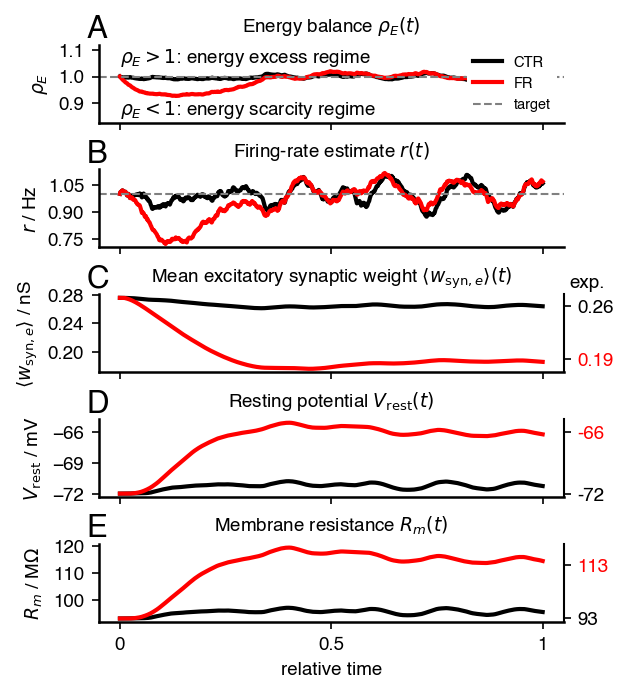

(<Figure size 600x750 with 8 Axes>,
 {'A': <Axes: label='A', title={'center': 'Energy balance $\\rho_E(t)$'}, ylabel='$\\rho_E$'>,
  'B': <Axes: label='B', title={'center': 'Firing-rate estimate $r(t)$'}, ylabel='$r$ / Hz'>,
  'C': <Axes: label='C', title={'center': 'Mean excitatory synaptic weight $\\langle w_{\\mathrm{syn},e} \\rangle(t)$'}, ylabel='$\\langle w_{\\mathrm{syn},e} \\rangle$ / nS'>,
  'D': <Axes: label='D', title={'center': 'Resting potential $V_{\\mathrm{rest}}(t)$'}, ylabel='$V_{\\mathrm{rest}}$ / mV'>,
  'E': <Axes: label='E', title={'center': 'Membrane resistance $R_m(t)$'}, xlabel='relative time', ylabel='$R_m$ / M$\\Omega$'>})

In [56]:
# plot Fig. data

ppf.fig_energy_IF_CTR_FR(time=[time_CTR_P, time_FR_P], rho_E_smooth=[rho_E_smooth_CTR_P, rho_E_smooth_FR_P], r_Ca_smooth=[r_Ca_dyn_smooth_CTR_P, r_Ca_dyn_smooth_FR_P], w_syn_e_dyn=[w_syn_e_dyn_CTR_P, w_syn_e_dyn_FR_P], V_rest_dyn=[V_rest_dyn_CTR_P, V_rest_dyn_FR_P], R_m_dyn=[R_m_dyn_CTR_P, R_m_dyn_FR_P], rho_E_target=rho_E_target, r_target=r_target,
    exp_w=[1, 1-0.28],
    exp_V_rest=[-72, -66],
    exp_R_m=[93, 113],
    downsample_factor=100,
    colors=['black', 'red'],
    fontsizes={'panelletterfontsize': 15},
    figsize=(4, 5),
    savename="5_supplements/fig_energy_IF_PP_control")


## Energy-dependent IF: V_rest blocked 

In [ ]:
# generating Fig. data
# define homogeneous synaptic input
T = 1000000 # in ms
N_syn, N_e, N_e_signal_ratio, N_i, rate_background_ratio, mu_rate_e, sigma_rate_e, mu_rate_i, sigma_rate_i, mu_weight_e, sigma_weight_e, mu_weight_i, sigma_weight_i = sif.synaptic_parameters(synaptic_scaling_mode='multiplicative')
w_e_0, w_i_0, spike_times_e, spike_times_i, r_e, r_i = sif.homogeneous_synaptic_input(T, N_e, N_i, mu_rate_e, sigma_rate_e, mu_rate_i, sigma_rate_i, mu_weight_e, sigma_weight_e, mu_weight_i, sigma_weight_i)

factor_w = 0.7
w_e = w_e_0 * 4 / 100 * factor_w
w_i = w_i_0 * 1 / 100 * factor_w

# simulate proportional energy-control and proportional-derivative rate-control
# load model parameters
C_m, V_rest, R_m, g_L, V_thresh, V_reset, Delta_T_ad, tau_w_ad, a_ad, b_ad, rate_window, tau_Ca, A_Ca, E_e, E_i, tau_e, tau_i, membrane_noise, rho_E_target, s_E, E_target_ATP, r_target, tau_r_smooth, tau_r_deriv, tau_E_smooth, dt_sim, dt_energy, tau_w_scale, tau_V_rest, tau_R_m, E_HK, V_Na, V_K, V_h, alpha_atp, e_c, A_R_m, A_overlap_AP, A_overlap_syn, d_axon, l_axon, d_soma, d_dendrite, l_dendrite, c_m_area, V_peak, N_boutons, E_glu_rec, E_Ca_ex = edIF.energy_dependent_sim_parameters(parameter_mode='CTR', membrane_noise=0.0, s_E=0.85)
# convert parameters to Brian2 units
T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, Delta_T_ad_b, tau_w_ad_b, a_ad_b, b_ad_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex = edIF.energy_parameters_brian(T, N_e, N_i, spike_times_e, spike_times_i, w_e, w_i, C_m, V_rest, R_m, g_L, V_thresh, V_reset, Delta_T_ad, tau_w_ad, a_ad, b_ad, rate_window, tau_Ca, A_Ca, E_e, E_i, tau_e, tau_i, membrane_noise, rho_E_target, s_E, E_target_ATP, r_target, tau_r_smooth, tau_r_deriv, tau_E_smooth, dt_sim, dt_energy, tau_w_scale, tau_V_rest, tau_R_m, E_HK, V_Na, V_K, V_h, alpha_atp, e_c, A_R_m, A_overlap_AP, A_overlap_syn, d_axon, l_axon, d_soma, d_dendrite, l_dendrite, c_m_area, V_peak, N_boutons, E_glu_rec, E_Ca_ex)

# block V_rest by slow dynamics
tau_V_rest_b = 1e30*ms

# CTR condition
s_E_CTR = 1.0
#time_CTR_PD_V_rest_blocked, V_m_CTR_PD_V_rest_blocked, spike_times_post_CTR_PD_V_rest_blocked, rate_estimate_post_CTR_PD_V_rest_blocked, I_syn_e_CTR_PD_V_rest_blocked, I_syn_i_CTR_PD_V_rest_blocked, g_e_CTR_PD_V_rest_blocked, g_i_CTR_PD_V_rest_blocked, E_cons_dyn_CTR_PD_V_rest_blocked, E_prod_dyn_CTR_PD_V_rest_blocked, rho_E_CTR_PD_V_rest_blocked, rho_E_smooth_CTR_PD_V_rest_blocked, rho_E_P_control_dyn_CTR_PD_V_rest_blocked, r_Ca_CTR_PD_V_rest_blocked, r_Ca_dyn_smooth_CTR_PD_V_rest_blocked, dr_Ca_dyn_smooth_CTR_PD_V_rest_blocked, r_PD_control_dyn_CTR_PD_V_rest_blocked, w_syn_e_dyn_CTR_PD_V_rest_blocked, V_rest_dyn_CTR_PD_V_rest_blocked, R_m_dyn_CTR_PD_V_rest_blocked = edIF.energy_dependent_LIF_P_energy_PD_rate_control(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_CTR, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex)
time_CTR_PD_V_rest_blocked, V_m_CTR_PD_V_rest_blocked, w_ad_CTR_PD_V_rest_blocked, spike_times_post_CTR_PD_V_rest_blocked, rate_estimate_post_CTR_PD_V_rest_blocked, I_syn_e_CTR_PD_V_rest_blocked, I_syn_i_CTR_PD_V_rest_blocked, g_e_CTR_PD_V_rest_blocked, g_i_CTR_PD_V_rest_blocked, E_cons_dyn_CTR_PD_V_rest_blocked, E_prod_dyn_CTR_PD_V_rest_blocked, rho_E_CTR_PD_V_rest_blocked, rho_E_smooth_CTR_PD_V_rest_blocked, rho_E_P_control_dyn_CTR_PD_V_rest_blocked, r_Ca_CTR_PD_V_rest_blocked, r_Ca_dyn_smooth_CTR_PD_V_rest_blocked, dr_Ca_dyn_smooth_CTR_PD_V_rest_blocked, r_PD_control_dyn_CTR_PD_V_rest_blocked, w_syn_e_dyn_CTR_PD_V_rest_blocked, V_rest_dyn_CTR_PD_V_rest_blocked, R_m_dyn_CTR_PD_V_rest_blocked = edIF.energy_dependent_AdExp_P_energy_PD_rate_control(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, Delta_T_ad_b, tau_w_ad_b, a_ad_b, b_ad_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_CTR, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex)

# FR condition
s_E_FR = 0.85
#time_FR_PD_V_rest_blocked, V_m_FR_PD_V_rest_blocked, spike_times_post_FR_PD_V_rest_blocked, rate_estimate_post_FR_PD_V_rest_blocked, I_syn_e_FR_PD_V_rest_blocked, I_syn_i_FR_PD_V_rest_blocked, g_e_FR_PD_V_rest_blocked, g_i_FR_PD_V_rest_blocked, E_cons_dyn_FR_PD_V_rest_blocked, E_prod_dyn_FR_PD_V_rest_blocked, rho_E_FR_PD_V_rest_blocked, rho_E_smooth_FR_PD_V_rest_blocked, rho_E_P_control_dyn_FR_PD_V_rest_blocked, r_Ca_FR_PD_V_rest_blocked, r_Ca_dyn_smooth_FR_PD_V_rest_blocked, dr_Ca_dyn_smooth_FR_PD_V_rest_blocked, r_PD_control_dyn_FR_PD_V_rest_blocked, w_syn_e_dyn_FR_PD_V_rest_blocked, V_rest_dyn_FR_PD_V_rest_blocked, R_m_dyn_FR_PD_V_rest_blocked = edIF.energy_dependent_LIF_P_energy_PD_rate_control(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_FR, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex)
time_FR_PD_V_rest_blocked, V_m_FR_PD_V_rest_blocked, w_ad_FR_PD_V_rest_blocked, spike_times_post_FR_PD_V_rest_blocked, rate_estimate_post_FR_PD_V_rest_blocked, I_syn_e_FR_PD_V_rest_blocked, I_syn_i_FR_PD_V_rest_blocked, g_e_FR_PD_V_rest_blocked, g_i_FR_PD_V_rest_blocked, E_cons_dyn_FR_PD_V_rest_blocked, E_prod_dyn_FR_PD_V_rest_blocked, rho_E_FR_PD_V_rest_blocked, rho_E_smooth_FR_PD_V_rest_blocked, rho_E_P_control_dyn_FR_PD_V_rest_blocked, r_Ca_FR_PD_V_rest_blocked, r_Ca_dyn_smooth_FR_PD_V_rest_blocked, dr_Ca_dyn_smooth_FR_PD_V_rest_blocked, r_PD_control_dyn_FR_PD_V_rest_blocked, w_syn_e_dyn_FR_PD_V_rest_blocked, V_rest_dyn_FR_PD_V_rest_blocked, R_m_dyn_FR_PD_V_rest_blocked = edIF.energy_dependent_AdExp_P_energy_PD_rate_control(T_b, N_e, N_i, spike_times_e, spike_times_i, w_e_b, w_i_b, C_m_b, V_rest_b, g_L_b, V_thresh_b, V_reset_b, Delta_T_ad_b, tau_w_ad_b, a_ad_b, b_ad_b, rate_window_b, tau_Ca_b, A_Ca_b, E_e_b, E_i_b, tau_e_b, tau_i_b, membrane_noise_b, rho_E_target, s_E_FR, E_target_ATP_b, r_target_b, tau_r_smooth_b, tau_r_deriv_b, tau_E_smooth_b, dt_sim_b, dt_energy_b, tau_w_scale_b, tau_V_rest_b, tau_R_m_b, E_HK_b, V_Na_b, V_K_b, V_h_b, alpha_atp, e_c_b, A_R_m, A_overlap_AP, A_overlap_syn, S_m_b, c_m_area_b, V_peak_b, N_boutons, E_glu_rec, E_Ca_ex)

# downsample data for smaller storage capacity
data_CTR_PD_V_rest_blocked = {"time": time_CTR_PD_V_rest_blocked, "V_m": V_m_CTR_PD_V_rest_blocked, "w_ad": w_ad_CTR_PD_V_rest_blocked, "spike_times_post": spike_times_post_CTR_PD_V_rest_blocked, "rate_estimate_post": rate_estimate_post_CTR_PD_V_rest_blocked, "I_syn_e": I_syn_e_CTR_PD_V_rest_blocked, "I_syn_i": I_syn_i_CTR_PD_V_rest_blocked, "g_e": g_e_CTR_PD_V_rest_blocked, "g_i": g_i_CTR_PD_V_rest_blocked, "E_cons_dyn": E_cons_dyn_CTR_PD_V_rest_blocked, "E_prod_dyn": E_prod_dyn_CTR_PD_V_rest_blocked, "rho_E": rho_E_CTR_PD_V_rest_blocked, "rho_E_smooth": rho_E_smooth_CTR_PD_V_rest_blocked, "rho_E_P_control_dyn": rho_E_P_control_dyn_CTR_PD_V_rest_blocked, "r_Ca": r_Ca_CTR_PD_V_rest_blocked, "r_Ca_smooth": r_Ca_dyn_smooth_CTR_PD_V_rest_blocked, "dr_Ca_smooth": dr_Ca_dyn_smooth_CTR_PD_V_rest_blocked, "r_PD_control_dyn": r_PD_control_dyn_CTR_PD_V_rest_blocked, "w_syn_e_dyn": w_syn_e_dyn_CTR_PD_V_rest_blocked, "V_rest_dyn": V_rest_dyn_CTR_PD_V_rest_blocked, "R_m_dyn": R_m_dyn_CTR_PD_V_rest_blocked, "rho_E_target": rho_E_target, "r_target": r_target_b/Hz, "s_E": s_E_CTR}
data_FR_PD_V_rest_blocked = {"time": time_FR_PD_V_rest_blocked, "V_m": V_m_FR_PD_V_rest_blocked, "w_ad": w_ad_FR_PD_V_rest_blocked, "spike_times_post": spike_times_post_FR_PD_V_rest_blocked, "rate_estimate_post": rate_estimate_post_FR_PD_V_rest_blocked, "I_syn_e": I_syn_e_FR_PD_V_rest_blocked, "I_syn_i": I_syn_i_FR_PD_V_rest_blocked, "g_e": g_e_FR_PD_V_rest_blocked, "g_i": g_i_FR_PD_V_rest_blocked, "E_cons_dyn": E_cons_dyn_FR_PD_V_rest_blocked, "E_prod_dyn": E_prod_dyn_FR_PD_V_rest_blocked, "rho_E": rho_E_FR_PD_V_rest_blocked, "rho_E_smooth": rho_E_smooth_FR_PD_V_rest_blocked, "rho_E_P_control_dyn": rho_E_P_control_dyn_FR_PD_V_rest_blocked, "r_Ca": r_Ca_FR_PD_V_rest_blocked, "r_Ca_smooth": r_Ca_dyn_smooth_FR_PD_V_rest_blocked, "dr_Ca_smooth": dr_Ca_dyn_smooth_FR_PD_V_rest_blocked, "r_PD_control_dyn": r_PD_control_dyn_FR_PD_V_rest_blocked, "w_syn_e_dyn": w_syn_e_dyn_FR_PD_V_rest_blocked, "V_rest_dyn": V_rest_dyn_FR_PD_V_rest_blocked, "R_m_dyn": R_m_dyn_FR_PD_V_rest_blocked, "rho_E_target": rho_E_target, "r_target": r_target_b/Hz, "s_E": s_E_FR}

data_CTR_PD_V_rest_blocked_downsampled = edIF.downsample_energy_data_dict(data_CTR_PD_V_rest_blocked, downsample_factor)
data_FR_PD_V_rest_blocked_downsampled = edIF.downsample_energy_data_dict(data_FR_PD_V_rest_blocked, downsample_factor)

with open("../Data/energy_dependent_IF/energy_IF_CTR_FR_PPD_V_rest_blocked_downsampled.pkl", "wb") as f: 
    pickle.dump({"CTR": data_CTR_PD_V_rest_blocked_downsampled, "FR": data_FR_PD_V_rest_blocked_downsampled, "downsample_factor": downsample_factor}, f)


In [58]:
# loading Fig. data for V_rest-blocked simulation
with open("../Data/energy_dependent_IF/energy_IF_CTR_FR_PPD_V_rest_blocked_downsampled.pkl", "rb") as f:
    fig_data_V_rest_blocked = pickle.load(f)

data_CTR_V_rest_blocked = fig_data_V_rest_blocked["CTR"]
data_FR_V_rest_blocked = fig_data_V_rest_blocked["FR"]

time_CTR_PD_V_rest_blocked, rho_E_smooth_CTR_PD_V_rest_blocked, r_Ca_dyn_smooth_CTR_PD_V_rest_blocked, dr_Ca_dyn_smooth_CTR_PD_V_rest_blocked, w_syn_e_dyn_CTR_PD_V_rest_blocked, V_rest_dyn_CTR_PD_V_rest_blocked, R_m_dyn_CTR_PD_V_rest_blocked, rho_E_target, r_target, s_E_CTR = [data_CTR_V_rest_blocked[k] for k in ["time", "rho_E_smooth", "r_Ca_smooth", "dr_Ca_smooth", "w_syn_e_dyn", "V_rest_dyn", "R_m_dyn", "rho_E_target", "r_target", "s_E"]]

time_FR_PD_V_rest_blocked, rho_E_smooth_FR_PD_V_rest_blocked, r_Ca_dyn_smooth_FR_PD_V_rest_blocked, dr_Ca_dyn_smooth_FR_PD_V_rest_blocked, w_syn_e_dyn_FR_PD_V_rest_blocked, V_rest_dyn_FR_PD_V_rest_blocked, R_m_dyn_FR_PD_V_rest_blocked, rho_E_target, r_target, s_E_FR = [data_FR_V_rest_blocked[k] for k in ["time", "rho_E_smooth", "r_Ca_smooth", "dr_Ca_smooth", "w_syn_e_dyn", "V_rest_dyn", "R_m_dyn", "rho_E_target", "r_target", "s_E"]]


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


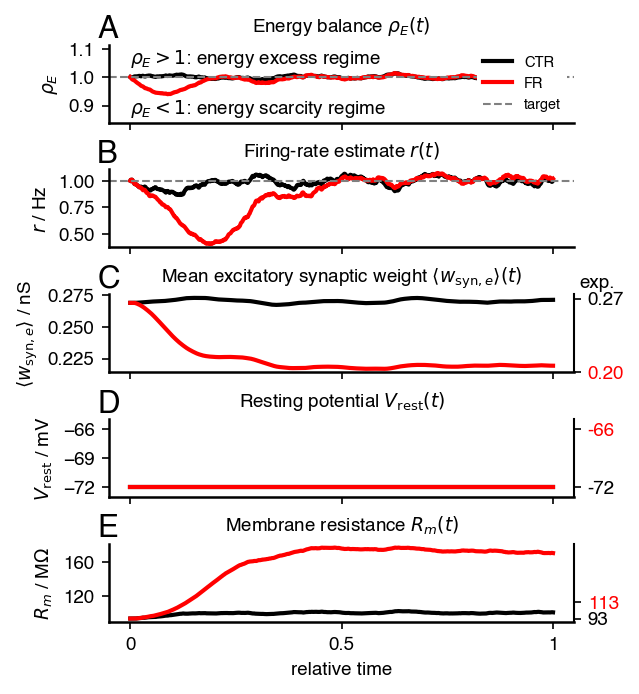

(<Figure size 600x750 with 8 Axes>,
 {'A': <Axes: label='A', title={'center': 'Energy balance $\\rho_E(t)$'}, ylabel='$\\rho_E$'>,
  'B': <Axes: label='B', title={'center': 'Firing-rate estimate $r(t)$'}, ylabel='$r$ / Hz'>,
  'C': <Axes: label='C', title={'center': 'Mean excitatory synaptic weight $\\langle w_{\\mathrm{syn},e} \\rangle(t)$'}, ylabel='$\\langle w_{\\mathrm{syn},e} \\rangle$ / nS'>,
  'D': <Axes: label='D', title={'center': 'Resting potential $V_{\\mathrm{rest}}(t)$'}, ylabel='$V_{\\mathrm{rest}}$ / mV'>,
  'E': <Axes: label='E', title={'center': 'Membrane resistance $R_m(t)$'}, xlabel='relative time', ylabel='$R_m$ / M$\\Omega$'>})

In [60]:

ppf.fig_energy_IF_CTR_FR(time=[time_CTR_PD_V_rest_blocked, time_FR_PD_V_rest_blocked], rho_E_smooth=[rho_E_smooth_CTR_PD_V_rest_blocked, rho_E_smooth_FR_PD_V_rest_blocked], r_Ca_smooth=[r_Ca_dyn_smooth_CTR_PD_V_rest_blocked, r_Ca_dyn_smooth_FR_PD_V_rest_blocked], w_syn_e_dyn=[w_syn_e_dyn_CTR_PD_V_rest_blocked, w_syn_e_dyn_FR_PD_V_rest_blocked], V_rest_dyn=[V_rest_dyn_CTR_PD_V_rest_blocked, V_rest_dyn_FR_PD_V_rest_blocked], R_m_dyn=[R_m_dyn_CTR_PD_V_rest_blocked, R_m_dyn_FR_PD_V_rest_blocked], rho_E_target=rho_E_target, r_target=r_target, 
    #r_Ca_var_smooth=[data_CTR_PD["r_Ca_var"], data_FR_PD["r_Ca_var"]],
    #r_var_target=data_CTR_PD["r_var_target"],
    #var_CV_mode="var",
    y_mode_V_rest="blocked",
    exp_w=[1, 1-0.28],
    exp_V_rest=[-72, -66],
    exp_R_m=[93, 113],
    downsample_factor=100,
    colors=['black', 'red'],
    fontsizes={'panelletterfontsize': 15},
    figsize=(4, 5),
    savename="5_supplements/fig_energy_IF_PPD_control_V_rest_blocked")


## Fitted high energy-information plane

In [ ]:
# generate Fig. data

# generate simulated data
grid_points = 11

R_m_values = np.linspace(50, 200, grid_points) # MOhm 
E_L_values = np.linspace(-90, -60, grid_points) # mV
w_scale_values = np.linspace(15, 240, grid_points) 
parameter_ranges = (R_m_values, E_L_values, w_scale_values)

model_mode = ['LIF', 'AdExp']
membrane_noise=1.0

results_AdExp = sf.multiple_grid_runs(number_grid_runs, parameter_ranges, model_mode, membrane_noise, starting_number=1, savename='Padamsey_grid')
# see python script: 3D_grid_run_cluster.py --> ready to store here

folder_path='../Data/Padamsey_grid'
results_mean =  af.load_and_process_multiple_results(savedname='Padamsey_grid',  model_mode=model_mode, folder_path=folder_path, results_mode='mean', spike_times_mode=False)

results_mean_spiking_trials = af.weight_results_by_spiking_trials(results_mean, results_number_data_points)


In [66]:
# loading Fig. data
with open('../Data/Padamsey_grid/updated_final_Padamsey_grid_small.pkl', 'rb') as f: 
    results_mean_spiking_trials = pickle.load(f) 


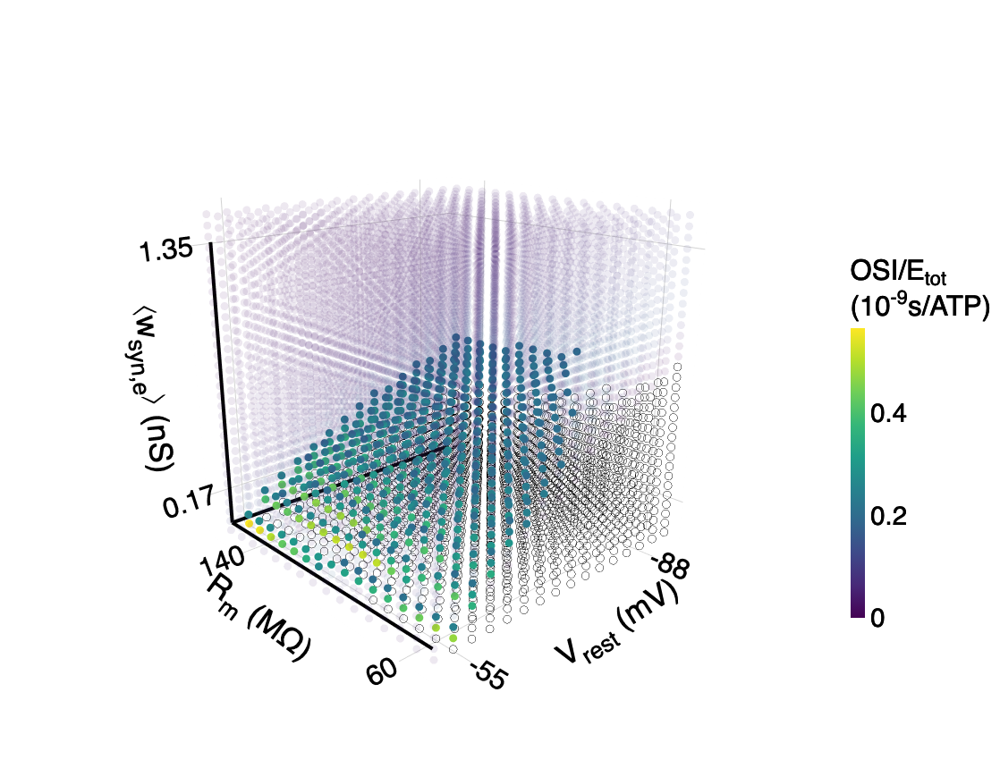

Plane fit on thresholded points (577 points):
z = a*x + b*y + c
a = -0.001752
b = -0.015919
c = -0.531773
R^2 = 0.908702

Plane fit on thresholded points
Number of points used: 577

Fitted relationship:
w_syn_e (nS) = -0.001752 · R_m (MOhm) + -0.015919 · E_L (mV) + -0.531773

Parameter interpretation:
dw_syn_e/dR_m = -0.001752 nS / MOhm
dw_syn_e/dE_L = -0.015919 nS / mV
offset         = -0.531773 nS



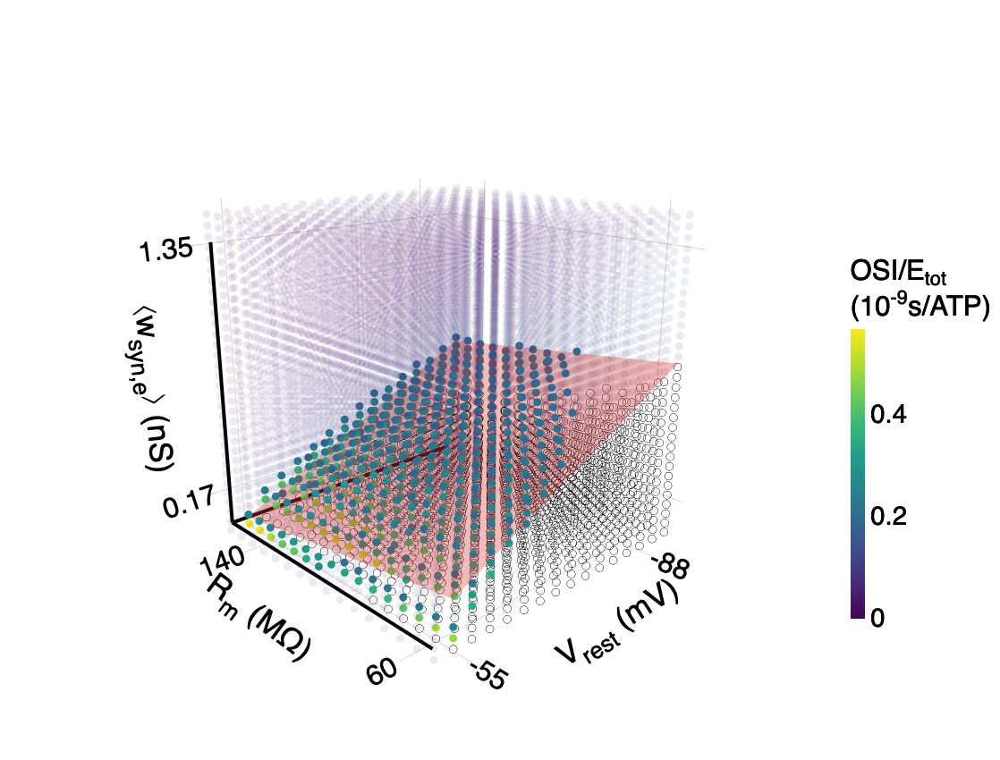

In [68]:
# plot Fig. data

fig = pf.plot_interactive_3D(results_mean_spiking_trials, 'OSI_per_energy', 'OSI_per_energy', lower_threshold = 0.2, interpolation = False, colorbar_mode = True, axes_mode=True, base_font_size=39, eye=dict(x=-1.81, y=1.7, z=0.8));
ppf.fig_3D_fitted_plane(fig, results_mean_spiking_trials, value_key='OSI_per_energy', lower_threshold=0.2, upper_threshold=None, use_translated_w_scale=True, plane_resolution=20, plane_opacity=0.9, print_results=True, name='OSI plane fit', figsize=(7,10), fontsizes=fontsizes, savename_mode=True);
   